In [1]:
# Optional: install segmentation-models in the notebook environment (commented out).
# If you need to install here, uncomment the next line.
# !pip install segmentation-models --quiet
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"


In [2]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"   # Ensure segmentation_models uses tf.keras


**imports**

In [3]:
import numpy as np
import cv2
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import segmentation_models as sm

# Training controls for quick runs (adjust as needed)
SIZE = 128
TRAIN_EPOCHS = int(os.environ.get('TRAIN_EPOCHS', 1))
BATCH_SIZE = int(os.environ.get('BATCH_SIZE', 4))

print("TensorFlow:", tf.__version__)
print("Segmentation Models:", sm.__version__)
print("NumPy:", np.__version__)


Segmentation Models: using `tf.keras` framework.
TensorFlow: 2.20.0
Segmentation Models: 1.0.1
NumPy: 2.4.2


In [4]:
# Dataset paths (edit to match your dataset). If paths missing, synthetic data will be generated for testing.
image_directory = os.environ.get('IMAGE_DIR', 'data/Images')
mask_directory  = os.environ.get('MASK_DIR', 'data/Masks')

# SIZE is defined in imports cell. Keep here for clarity.
SIZE = SIZE  # 128 by default

# Quick configuration summary
print('image_directory =', image_directory)
print('mask_directory  =', mask_directory)
print('SIZE            =', SIZE)
print('TRAIN_EPOCHS    =', TRAIN_EPOCHS)
print('BATCH_SIZE      =', BATCH_SIZE)


image_directory = data/Images
mask_directory  = data/Masks
SIZE            = 128
TRAIN_EPOCHS    = 1
BATCH_SIZE      = 4


In [5]:
image_dataset = []
mask_dataset  = []

if os.path.exists(image_directory) and os.path.exists(mask_directory):
    images = sorted([f for f in os.listdir(image_directory) if f.lower().endswith(('.jpg','.jpeg','.png'))])

    for image_name in images:
        # Only process image files
        img_path = os.path.join(image_directory, image_name)
        if not os.path.exists(img_path):
            continue
        image = cv2.imread(img_path)
        if image is None:
            print(f"Failed to read image: {img_path}")
            continue
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (SIZE, SIZE))
        image_dataset.append(image.astype(np.float32) / 255.0)

        # Build the mask filename by base name and try common extensions
        base_name, _ = os.path.splitext(image_name)
        found_mask = False
        for ext in ['.png', '.jpg', '.jpeg']:
            mask_path = os.path.join(mask_directory, base_name + ext)
            if os.path.exists(mask_path):
                mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                if mask is None:
                    continue
                mask = cv2.resize(mask, (SIZE, SIZE))
                mask_dataset.append((mask.astype(np.float32) / 255.0))
                found_mask = True
                break

        if not found_mask:
            print(f"Mask for {image_name} not found in any tried extension!")

else:
    # Fallback: generate small synthetic dataset for testing/demo
    print("Dataset folders not found — generating synthetic data for a quick run.")
    n_samples = 10
    for i in range(n_samples):
        img = (np.random.rand(SIZE, SIZE, 3) * 255).astype(np.float32) / 255.0
        mask = (np.random.rand(SIZE, SIZE) > 0.7).astype(np.float32)
        image_dataset.append(img)
        mask_dataset.append(mask)

# Ensure arrays
image_dataset = np.array(image_dataset, dtype=np.float32)
mask_dataset  = np.array(mask_dataset, dtype=np.float32)
if mask_dataset.ndim == 3:
    mask_dataset = np.expand_dims(mask_dataset, axis=-1)

print("Total Images:", len(image_dataset))
print("Total Masks :", len(mask_dataset))


Dataset folders not found — generating synthetic data for a quick run.
Total Images: 10
Total Masks : 10


In [6]:
# Split dataset (if enough samples available)
if len(image_dataset) > 1:
    X_train, X_val, y_train, y_val = train_test_split(
        image_dataset, mask_dataset, test_size=0.2, random_state=42
    )
else:
    # not enough data to split — use all for both train and val (quick smoke test)
    X_train = image_dataset
    X_val = image_dataset
    y_train = mask_dataset
    y_val = mask_dataset

print('X_train.shape =', getattr(X_train, 'shape', None))
print('y_train.shape =', getattr(y_train, 'shape', None))


X_train.shape = (8, 128, 128, 3)
y_train.shape = (8, 128, 128, 1)


**U-Net**

In [7]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x

def encoder_block(x, filters):
    c = conv_block(x, filters)
    p = layers.MaxPooling2D((2,2))(c)
    return c, p

def decoder_block(x, skip, filters):
    us = layers.Conv2DTranspose(filters, (2,2), strides=2, padding="same")(x)
    concat = layers.Concatenate()([us, skip])
    c = conv_block(concat, filters)
    return c

def build_unet(input_shape=(SIZE,SIZE,3)):
    inputs = layers.Input(input_shape)

    s1, p1 = encoder_block(inputs, 64)
    s2, p2 = encoder_block(p1, 128)
    s3, p3 = encoder_block(p2, 256)
    s4, p4 = encoder_block(p3, 512)

    b1 = conv_block(p4, 1024)

    d1 = decoder_block(b1, s4, 512)
    d2 = decoder_block(d1, s3, 256)
    d3 = decoder_block(d2, s2, 128)
    d4 = decoder_block(d3, s1, 64)

    outputs = layers.Conv2D(1, (1,1), activation="sigmoid")(d4)
    return models.Model(inputs, outputs)

basic_unet = build_unet()
basic_unet.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[sm.metrics.iou_score, sm.metrics.f1_score],
)
basic_unet.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_4[0][0]  

 Total params: 31,055,297 (118.47 MB)

 Trainable params: 31,043,521 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

In [8]:
if len(X_train) > 0:
    history_basic = basic_unet.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=BATCH_SIZE,
        epochs=TRAIN_EPOCHS,
    )
else:
    print('No training data available — skipping basic_unet.fit')


2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - f1-score: 0.3438 - iou_score: 0.2076 - loss: 0.7007 - val_f1-score: 0.3733 - val_iou_score: 0.2295 - val_loss: 0.6929


**attention unet**

In [9]:
from tensorflow.keras import layers, models

def attention_gate(x, g, filters):
    """Channel attention gate (robust to mismatched spatial sizes).
    Uses global pooling on gating signal to produce channel-wise attention.
    """
    # Project skip connection to desired filter count
    x_proj = layers.Conv2D(filters, 1, padding="same", activation=None)(x)

    # Global context from gating signal
    g_gap = layers.GlobalAveragePooling2D()(g)
    dense = layers.Dense(filters // 2, activation='relu')(g_gap)
    dense = layers.Dense(filters, activation='sigmoid')(dense)
    channel_att = layers.Reshape((1,1,filters))(dense)

    # Apply channel attention to skip features
    out = layers.Multiply()([x_proj, channel_att])
    return out


def build_attention_unet(input_shape=(SIZE,SIZE,3)):
    inputs = layers.Input(input_shape)

    # Encoder
    s1, p1 = encoder_block(inputs, 64)
    s2, p2 = encoder_block(p1, 128)
    s3, p3 = encoder_block(p2, 256)
    s4, p4 = encoder_block(p3, 512)

    # Bottleneck
    b1 = conv_block(p4, 1024)

    # Decoder with Attention (channel-wise)
    att1 = attention_gate(s4, b1, 512)
    d1 = decoder_block(b1, att1, 512)

    att2 = attention_gate(s3, d1, 256)
    d2 = decoder_block(d1, att2, 256)

    att3 = attention_gate(s2, d2, 128)
    d3 = decoder_block(d2, att3, 128)

    att4 = attention_gate(s1, d3, 64)
    d4 = decoder_block(d3, att4, 64)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(d4)
    return models.Model(inputs, outputs)


In [10]:
attention_unet = build_attention_unet()
attention_unet.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[sm.metrics.iou_score, sm.metrics.f1_score],
)

if len(X_train) > 0:
    history_att = attention_unet.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=BATCH_SIZE,
        epochs=TRAIN_EPOCHS,
    )
else:
    print('No training data available — skipping attention_unet.fit')


2/2 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - f1-score: 0.3585 - iou_score: 0.2184 - loss: 0.7394 - val_f1-score: 0.3731 - val_iou_score: 0.2293 - val_loss: 0.6923


**Residual unet**

In [11]:
def residual_block(x, filters):
    shortcut = layers.Conv2D(filters, 1, padding="same")(x)
    c = layers.Conv2D(filters, 3, padding="same")(x)
    c = layers.BatchNormalization()(c)
    c = layers.ReLU()(c)
    c = layers.Conv2D(filters, 3, padding="same")(c)
    c = layers.BatchNormalization()(c)
    return layers.ReLU()(layers.Add()([shortcut, c]))

def build_resunet(input_shape=(SIZE,SIZE,3)):
    inputs = layers.Input(input_shape)

    # Encoder
    s1 = residual_block(inputs, 64); p1 = layers.MaxPooling2D(2)(s1)
    s2 = residual_block(p1, 128); p2 = layers.MaxPooling2D(2)(s2)
    s3 = residual_block(p2, 256); p3 = layers.MaxPooling2D(2)(s3)
    s4 = residual_block(p3, 512); p4 = layers.MaxPooling2D(2)(s4)

    # Bottleneck
    b1 = residual_block(p4, 1024)

    # Decoder
    d1 = decoder_block(b1, s4, 512)
    d2 = decoder_block(d1, s3, 256)
    d3 = decoder_block(d2, s2, 128)
    d4 = decoder_block(d3, s1, 64)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(d4)
    return models.Model(inputs, outputs)

resunet = build_resunet()
resunet.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[sm.metrics.iou_score, sm.metrics.f1_score],
)

if len(X_train) > 0:
    history_res = resunet.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=BATCH_SIZE,
        epochs=TRAIN_EPOCHS,
    )
else:
    print('No training data available — skipping resunet.fit')


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 789ms/step - f1-score: 0.3810 - iou_score: 0.2353 - loss: 0.7896WARNING:tensorflow:6 out of the last 9 calls to <function TensorFlowTrainer._make_function.<locals>.multi_step_on_iterator at 0x365992700> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - f1-score: 0.3792 - iou_score: 0.2340 - loss: 0.7854 - val_f1-score: 0.3736 - val_iou_score: 0.2297 - val_loss: 0.6938


In [12]:
unet_resnet = sm.Unet(
    backbone_name='resnet34',
    encoder_weights='imagenet',  # Pretrained weights
    classes=1,
    activation='sigmoid'
)

unet_resnet.compile(
    optimizer='adam',
    loss=sm.losses.bce_jaccard_loss,
    metrics=[sm.metrics.iou_score, sm.metrics.f1_score],
)

if len(X_train) > 0:
    history_resnet = unet_resnet.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=BATCH_SIZE,
        epochs=TRAIN_EPOCHS,
    )
else:
    print('No training data available — skipping unet_resnet.fit')


2/2 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - f1-score: 0.3945 - iou_score: 0.2457 - loss: 1.6048 - val_f1-score: 0.3960 - val_iou_score: 0.2469 - val_loss: 1.5495


In [13]:
fpn_model = sm.FPN(
    backbone_name='resnet34',
    encoder_weights='imagenet',
    classes=1,
    activation='sigmoid'
)

fpn_model.compile(
    optimizer='adam',
    loss=sm.losses.bce_jaccard_loss,
    metrics=[sm.metrics.iou_score, sm.metrics.f1_score],
)

if len(X_train) > 0:
    history_fpn = fpn_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=BATCH_SIZE,
        epochs=TRAIN_EPOCHS,
    )
else:
    print('No training data available — skipping fpn_model.fit')


2/2 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - f1-score: 0.3688 - iou_score: 0.2262 - loss: 1.6420 - val_f1-score: 0.0384 - val_iou_score: 0.0196 - val_loss: 2.5129


In [14]:
from tensorflow.keras import layers, models

def attention_gate(x, g, filters):
    """Attention gate (channel-wise) to be robust to spatial mismatches."""
    x_proj = layers.Conv2D(filters, 1, padding="same", activation=None)(x)
    g_gap = layers.GlobalAveragePooling2D()(g)
    dense = layers.Dense(filters // 2, activation='relu')(g_gap)
    dense = layers.Dense(filters, activation='sigmoid')(dense)
    channel_att = layers.Reshape((1,1,filters))(dense)
    out = layers.Multiply()([x_proj, channel_att])
    return out

def build_attention_unet(input_shape=(SIZE,SIZE,3)):
    inputs = layers.Input(input_shape)

    # Encoder
    s1, p1 = encoder_block(inputs, 64)
    s2, p2 = encoder_block(p1, 128)
    s3, p3 = encoder_block(p2, 256)
    s4, p4 = encoder_block(p3, 512)

    # Bottleneck
    b1 = conv_block(p4, 1024)

    # Decoder with Attention
    att1 = attention_gate(s4, b1, 512)
    d1 = decoder_block(b1, att1, 512)

    att2 = attention_gate(s3, d1, 256)
    d2 = decoder_block(d1, att2, 256)

    att3 = attention_gate(s2, d2, 128)
    d3 = decoder_block(d2, att3, 128)

    att4 = attention_gate(s1, d3, 64)
    d4 = decoder_block(d3, att4, 64)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(d4)
    return models.Model(inputs, outputs)

# Compile & train guard
attention_unet = build_attention_unet()
attention_unet.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[sm.metrics.iou_score, sm.metrics.f1_score],
)

if len(X_train) > 0:
    history_att = attention_unet.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=BATCH_SIZE,
        epochs=TRAIN_EPOCHS,
    )
else:
    print('No training data available — skipping attention_unet.fit')


2/2 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - f1-score: 0.3969 - iou_score: 0.2476 - loss: 0.9054 - val_f1-score: 0.3737 - val_iou_score: 0.2298 - val_loss: 0.6944


In [15]:
import matplotlib.pyplot as plt
import numpy as np

def predict_and_show(model, X, y, idx=None, threshold=0.5, title="Model"):
    if idx is None:
        idx = np.random.randint(0, len(X))
    image  = X[idx]
    gt_mask = y[idx]
    pred_mask = model.predict(image[np.newaxis,...])[0,...,0]
    pred_mask_bin = (pred_mask > threshold).astype(np.float32)

    plt.figure(figsize=(12,4))
    plt.suptitle(title, fontsize=14)
    
    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(gt_mask[...,0], cmap='gray')
    plt.title("Ground Truth")
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.imshow(pred_mask_bin, cmap='gray')
    plt.title("Prediction")
    plt.axis('off')
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step


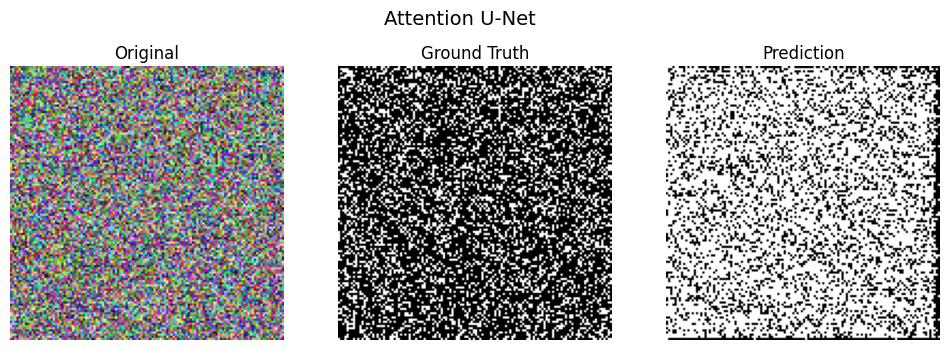

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step


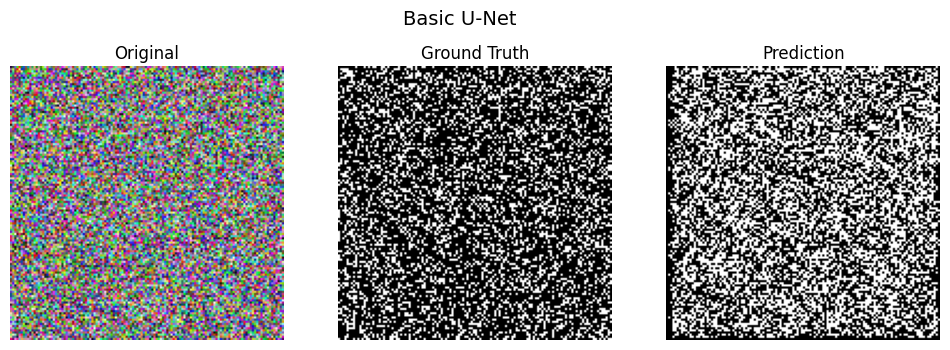

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step


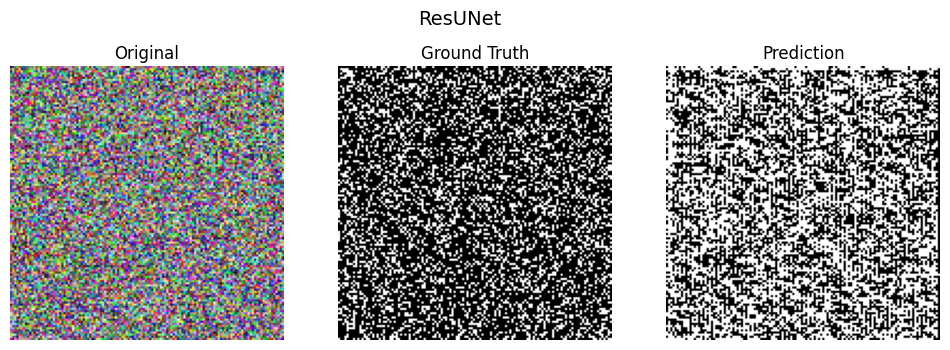

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 647ms/step


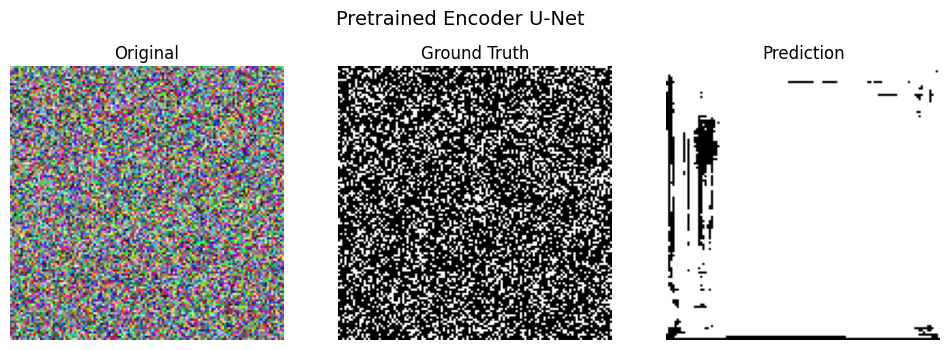

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 680ms/step


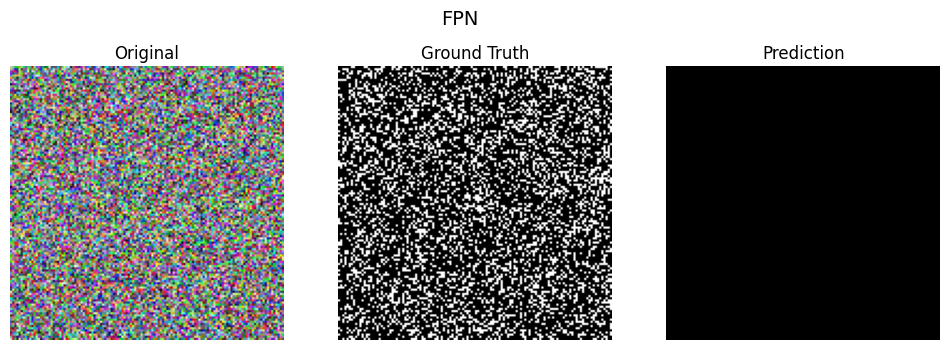

In [16]:
predict_and_show(attention_unet, X_val, y_val, title="Attention U-Net")
predict_and_show(basic_unet, X_val, y_val, title="Basic U-Net")
predict_and_show(resunet, X_val, y_val, title="ResUNet")
predict_and_show(unet_resnet, X_val, y_val, title="Pretrained Encoder U-Net")
predict_and_show(fpn_model, X_val, y_val, title="FPN")


In [17]:
import pandas as pd

def evaluate_model(model, X_val, y_val):
    try:
        results = model.evaluate(X_val, y_val, verbose=0)
        # metrics ordering: loss, iou_score, f1_score when compiled that way
        if len(results) >= 3:
            return results[1], results[2]
        elif len(results) == 2:
            return results[1], None
        else:
            return None, None
    except Exception as e:
        print('Evaluation failed for model:', getattr(model, 'name', str(model)), e)
        return None, None

scores = []
for name, model in [
    ("Basic U-Net", globals().get('basic_unet')),
    ("Attention U-Net", globals().get('attention_unet')),
    ("ResUNet", globals().get('resunet')),
    ("Pretrained Encoder U-Net", globals().get('unet_resnet')),
    ("FPN", globals().get('fpn_model')),
]:
    if model is None:
        print(f"Model {name} not available — skipping evaluation")
        continue
    iou, f1 = evaluate_model(model, X_val, y_val)
    scores.append([name, iou, f1])

if len(scores) > 0:
    results_df = pd.DataFrame(scores, columns=["Model","IoU Score","F1/Dice Score"])
    results_df = results_df.sort_values(by="IoU Score", ascending=False).reset_index(drop=True)
    display(results_df)
else:
    print('No model evaluations available')


,Model,IoU Score,F1/Dice Score
0,Pretrained Encoder U-Net,0.246883,0.396000
1,Attention U-Net,0.229814,0.373738
2,ResUNet,0.229694,0.373579
3,Basic U-Net,0.229485,0.373303
4,FPN,0.019586,0.038419


In [18]:
best_model_name = results_df.iloc[0]["Model"]
print("🏆 Best Model Based on IoU:", best_model_name)


🏆 Best Model Based on IoU: Pretrained Encoder U-Net
